In [1]:
from __future__ import annotations

import json
import os
import re
import time
from datetime import date, datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from dotenv import load_dotenv

ROOT = Path.cwd()
load_dotenv(ROOT / ".env")

API_KEY = os.getenv("PokeEDU_KEY", "").strip()
BASE_URL = "https://api.pokewallet.io"
HEADERS = {"User-Agent": "WebDataScience/1.0 (edgar.soberonmunoz@colorado.edu)"}
PAUSE_SECONDS = 0.8  # free tier: 100/hour, 1000/day
REFERENCE_DATE = date.today()

RAW_DIR = ROOT / "data" / "raw_pokewallet"
PROC_DIR = ROOT / "data" / "processed"
SAMPLE_DIR = ROOT / "data" / "sample"
FIG_DIR = ROOT / "figures"
for d in (RAW_DIR, PROC_DIR, SAMPLE_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

if not API_KEY or not API_KEY.startswith("pk_"):
    raise SystemExit(
        "Missing/invalid PokeEDU_KEY. Put PokeEDU_KEY=pk_live_... in .env and re-run."
    )

SESSION = requests.Session()
SESSION.headers.update({
    **HEADERS,
    "Accept": "application/json",
    "X-API-Key": API_KEY,  
})

print("User-Agent:", HEADERS["User-Agent"])
print("API key loaded:", API_KEY[:12] + "…" + API_KEY[-4:])
print("Reference date for age:", REFERENCE_DATE.isoformat())

User-Agent: WebDataScience/1.0 (edgar.soberonmunoz@colorado.edu)
API key loaded: pk_live_86c7…7e8d
Reference date for age: 2026-11-15


In [2]:
def polite_get(path: str, params: dict | None = None) -> dict:
    """GET JSON with pauses, status checks, and 429 backoff."""
    url = f"{BASE_URL}{path}"
    params = params or {}
    for attempt in range(1, 5):
        time.sleep(PAUSE_SECONDS)
        resp = SESSION.get(url, params=params, timeout=60)
        remain_h = resp.headers.get("X-RateLimit-Remaining-Hour")
        if remain_h is not None:
            print(f"  {path} → {resp.status_code} | remaining this hour: {remain_h}")
        if resp.status_code == 429:
            wait = max(30, PAUSE_SECONDS * (3 ** attempt))
            print(f"  rate limited; sleeping {wait:.0f}s")
            time.sleep(wait)
            continue
        if resp.status_code >= 400:
            raise RuntimeError(
                f"{resp.status_code} {url} params={params}\n{resp.text[:500]}"
            )
        return resp.json()
    raise RuntimeError(f"Gave up on {url} after retries")


def parse_release_date(value) -> date | None:
    """Parse PokéWallet dates like '28th March, 2025' or ISO strings."""
    if value is None or (isinstance(value, float) and pd.isna(value)):
        return None
    if not isinstance(value, str):
        value = str(value)
    value = value.strip()
    if not value or value.lower() in {"nan", "none", "nat"}:
        return None
    try:
        return date.fromisoformat(value[:10])
    except ValueError:
        pass
    cleaned = re.sub(r"(\d+)(st|nd|rd|th)", r"\1", value)
    for fmt in ("%d %B, %Y", "%d %B %Y", "%B %d, %Y", "%Y-%m-%d"):
        try:
            return datetime.strptime(cleaned, fmt).date()
        except ValueError:
            continue
    return None


def best_tcgplayer_market_price(card: dict) -> tuple[float | None, str | None]:
    """Highest positive TCGPlayer market_price across finish variants."""
    tcg = card.get("tcgplayer") or {}
    best = None
    label = None
    for row in tcg.get("prices") or []:
        mp = row.get("market_price")
        if isinstance(mp, (int, float)) and mp > 0:
            if best is None or float(mp) > best:
                best = float(mp)
                label = row.get("sub_type_name") or "unknown"
    return best, label


print("Helpers ready.")

Helpers ready.


## 2. Collect sets, then sample English main sets across eras

In [3]:
collected_at = datetime.now(timezone.utc).isoformat()
print("GET /sets …")
sets_payload = polite_get("/sets")
(RAW_DIR / "sets.json").write_text(json.dumps(sets_payload, indent=2), encoding="utf-8")

sets_df = pd.DataFrame(sets_payload.get("data") or [])
sets_df["release_date_parsed"] = sets_df["release_date"].apply(parse_release_date)
print(f"Total sets: {len(sets_df):,}")
print("Language value counts:")
display(sets_df["language"].value_counts(dropna=False).head(15))

# Docs: English sets use language code "eng"
eng = sets_df[
    (sets_df["language"].astype(str).str.lower() == "eng")
    & sets_df["release_date_parsed"].notna()
    & sets_df["set_code"].notna()
    & (sets_df["card_count"].fillna(0) >= 40)
].copy()
eng["year"] = eng["release_date_parsed"].map(lambda d: d.year)
print(f"English candidate sets (≥40 cards, dated): {len(eng):,}")
display(eng.sort_values("release_date_parsed")[["name", "set_code", "set_id", "release_date", "card_count"]].head(8))

GET /sets …
  /sets → 200 | remaining this hour: 98
Total sets: 856
Language value counts:


language
jap    525
eng    269
chn     61
che      1
Name: count, dtype: int64

English candidate sets (≥40 cards, dated): 178


,name,set_code,set_id,release_date,card_count
398,Nintendo Promos,PR,1423,"1st January, 1999",95
575,SM Promos,SMP,1861,"1st January, 1999",334
802,Wizards Promos,WP,-192,"1st January, 1999",55
459,Professor Program Promos,PPP,2332,"1st January, 1999",45
25,Base Set,BS,604,"9th January, 1999",103
26,Base Set (Shadowless),BSS,1663,"9th January, 1999",102
819,XY Base Set,XY,1387,"9th January, 1999",147
574,SM Base Set,SM01,1863,"9th January, 1999",172


In [4]:
# Prefer recognizable main expansions when present; otherwise auto-pick by era.
PREFERRED_CODES = [
    "BS", "Base", "JU", "FO",          # vintage-ish codes if present
    "RS", "EX", "DX", "DP", "BLW",
    "XY", "SUM", "SM",
    "SSH", "SWSH", "SWSH1", "DAA", "SWSH3",
    "SVI", "SV1", "OBF", "PAR", "MEW", "JTG",
]

NAME_HINTS = [
    "Base Set",
    "Jungle",
    "Fossil",
    "Ruby & Sapphire",
    "Diamond & Pearl",
    "Black & White",
    "XY",
    "Sun & Moon",
    "Sword & Shield",
    "Darkness Ablaze",
    "Scarlet & Violet",
    "Obsidian Flames",
    "Paradox Rift",
    "151",
]

preferred = eng[
    eng["set_code"].astype(str).str.upper().isin([c.upper() for c in PREFERRED_CODES])
    | eng["name"].isin(NAME_HINTS)
    | eng["name"].str.contains("Scarlet & Violet|Sword & Shield|Base Set|Darkness Ablaze|Paradox Rift|Obsidian Flames|Sun & Moon|Diamond & Pearl|Black & White|Ruby & Sapphire", case=False, na=False)
].copy()

# Auto-stratify: one set near each era bin
bins = [
    (1999, 2003),
    (2004, 2010),
    (2011, 2016),
    (2017, 2020),
    (2021, 2023),
    (2024, 2026),
]
auto_rows = []
for lo, hi in bins:
    block = eng[(eng["year"] >= lo) & (eng["year"] <= hi)].sort_values("card_count", ascending=False)
    # skip obvious promo-heavy names when possible
    block = block[~block["name"].str.contains("Promo|McDonald|Trainer Kit|Box Topper", case=False, na=False)]
    if not block.empty:
        auto_rows.append(block.iloc[0])

auto = pd.DataFrame(auto_rows)
chosen = (
    pd.concat([preferred, auto], ignore_index=True)
    .drop_duplicates(subset=["set_id"])
    .sort_values("release_date_parsed")
    .head(8)
)

print("Chosen English sets:")
display(chosen[["name", "set_code", "set_id", "release_date", "card_count", "year"]])
if chosen.empty:
    raise SystemExit("No English sets selected — inspect eng and adjust filters.")

Chosen English sets:


,name,set_code,set_id,release_date,card_count,year
0,Base Set,BS,604,"9th January, 1999",103,1999
1,Base Set (Shadowless),BSS,1663,"9th January, 1999",102,1999
24,XY Base Set,XY,1387,"9th January, 1999",147,1999
12,SM Base Set,SM01,1863,"9th January, 1999",172,1999
9,Jungle,JU,635,"16th June, 1999",64,1999
8,Fossil,FO,630,"10th October, 1999",62,1999
2,Base Set 2,BS2,605,"24th February, 2000",130,2000
7,Expedition,EX,1375,"15th September, 2002",165,2002


In [5]:
def search_cards_for_set(set_code: str, set_id: str, max_pages: int = 2, limit: int = 100) -> list[dict]:
    """Search by set_code, then keep cards belonging to this set_id."""
    kept: list[dict] = []
    for page in range(1, max_pages + 1):
        payload = polite_get("/search", {"q": set_code, "page": page, "limit": limit})
        results = payload.get("results") or []
        for card in results:
            info = card.get("card_info") or {}
            if info.get("product_type") not in (None, "card"):
                # sealed products are priced but excluded from this analysis
                if info.get("product_type") == "sealed":
                    continue
            # Prefer exact set_id match (docs: set_id is the stable join key)
            sid = str(info.get("set_id") or "")
            scode = str(info.get("set_code") or "")
            if sid and sid != str(set_id):
                # some responses put numeric id into set_code; allow that
                if scode != str(set_id) and scode.upper() != str(set_code).upper():
                    continue
            kept.append(card)
        pag = payload.get("pagination") or {}
        total_pages = int(pag.get("total_pages") or page)
        print(f"  search {set_code} page {page}/{total_pages}: raw={len(results)} kept_running={len(kept)}")
        if page >= total_pages or not results:
            break
    return kept


raw_cards: list[dict] = []
meta_by_id = {
    str(r.set_id): {
        "set_code": str(r.set_code),
        "set_name": r.name,
        "release_date": r.release_date_parsed,
    }
    for r in chosen.itertuples()
}

for r in chosen.itertuples():
    set_code = str(r.set_code)
    set_id = str(r.set_id)
    print(f"Collecting {r.name} ({set_code} / set_id={set_id}) …")
    cards = search_cards_for_set(set_code, set_id, max_pages=2, limit=100)
    (RAW_DIR / f"search_{set_code}_{set_id}.json").write_text(
        json.dumps(cards, indent=2), encoding="utf-8"
    )
    for card in cards:
        card = dict(card)
        card["_collected_at"] = collected_at
        card["_set_id"] = set_id
        card["_set_code"] = set_code
        card["_set_name"] = r.name
        card["_release_date"] = r.release_date_parsed.isoformat()
        raw_cards.append(card)

manifest = {
    "source": "PokéWallet API",
    "base_url": BASE_URL,
    "docs": "https://pokewallet.io/api-docs",
    "collector": "Edgar Soberon <edgar.soberonmunoz@colorado.edu>",
    "user_agent": HEADERS["User-Agent"],
    "collected_at_utc": collected_at,
    "n_cards_raw": len(raw_cards),
    "sets": chosen[["name", "set_code", "set_id", "release_date", "card_count"]].to_dict(orient="records"),
}
(RAW_DIR / "manifest.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
(RAW_DIR / "cards_raw.json").write_text(json.dumps(raw_cards, indent=2), encoding="utf-8")
print(f"Saved {len(raw_cards)} raw card records to {RAW_DIR}")

  /search → 200 | remaining this hour: 97
  search BS page 1/7: raw=100 kept_running=100
  /search → 200 | remaining this hour: 96
  search BS page 2/7: raw=100 kept_running=103
  /search → 200 | remaining this hour: 95
  search BSS page 1/2: raw=100 kept_running=100
  /search → 200 | remaining this hour: 94
  search BSS page 2/2: raw=11 kept_running=102
  /search → 200 | remaining this hour: 93
  search XY page 1/8: raw=100 kept_running=0
  /search → 200 | remaining this hour: 92
  search XY page 2/8: raw=100 kept_running=0
  /search → 200 | remaining this hour: 91
  search SM01 page 1/3: raw=100 kept_running=98
  /search → 200 | remaining this hour: 90
  search SM01 page 2/3: raw=100 kept_running=172
  /search → 200 | remaining this hour: 89
  search JU page 1/7: raw=100 kept_running=0
  /search → 200 | remaining this hour: 88
  search JU page 2/7: raw=100 kept_running=0
  /search → 200 | remaining this hour: 87
  search FO page 1/7: raw=100 kept_running=52
  /search → 200 | remainin

## 4. Clean 

In [6]:
rows = []
for card in raw_cards:
    info = card.get("card_info") or {}
    if info.get("product_type") == "sealed":
        continue
    price, variant = best_tcgplayer_market_price(card)
    rel = parse_release_date(card.get("_release_date"))
    age = round((REFERENCE_DATE - rel).days / 365.25, 2) if rel else None
    rows.append({
        "card_id": card.get("id"),
        "card_name": info.get("name"),
        "set_id": card.get("_set_id") or info.get("set_id"),
        "set_code": card.get("_set_code") or info.get("set_code"),
        "set_name": card.get("_set_name") or info.get("set_name"),
        "release_date": rel.isoformat() if rel else None,
        "age_years": age,
        "rarity": info.get("rarity"),
        "card_number": info.get("card_number"),
        "variant_price_source": variant,
        "market_price_usd": price,
        "collected_at_utc": card.get("_collected_at"),
    })

df = pd.DataFrame(rows)
before = len(df)
df = df.dropna(subset=["card_id", "card_name", "set_id", "rarity", "release_date", "market_price_usd"])
df = df[df["market_price_usd"] > 0]
df = df.drop_duplicates(subset=["card_id"])
df = df.sort_values(["release_date", "set_code", "card_id"]).reset_index(drop=True)


def rarity_bucket(r: str) -> str:
    r_low = str(r).lower()
    if r_low == "common" or r_low.startswith("common"):
        return "Common"
    if "uncommon" in r_low:
        return "Uncommon"
    if any(x in r_low for x in ["secret", "illustration", "special art", "hyper", "gold", "rainbow", "art rare"]):
        return "Secret/Special"
    if any(x in r_low for x in ["ultra", "double rare", "rare holo v", "vmax", "vstar", " ex", "gx"]):
        return "Ultra+"
    if "rare" in r_low or "holo" in r_low:
        return "Rare"
    return "Other"


def era_label(y: float) -> str:
    if y >= 20:
        return "20+ years"
    if y >= 10:
        return "10–20 years"
    if y >= 5:
        return "5–10 years"
    return "under 5 years"


df["rarity_bucket"] = df["rarity"].map(rarity_bucket)
df["era"] = df["age_years"].map(era_label)

clean_path = PROC_DIR / "cards_clean_pokewallet.csv"
sample_path = SAMPLE_DIR / "cards_clean_pokewallet_sample.csv"
df.to_csv(clean_path, index=False)
df.sample(n=min(25, len(df)), random_state=4617).sort_values(
    ["release_date", "card_id"]
).to_csv(sample_path, index=False)

print(f"Cleaning: {before} → {len(df)} rows (dropped {before - len(df)})")
print(f"Sets: {df['set_id'].nunique()} | Rarities: {df['rarity'].nunique()}")
if len(df) == 0:
    raise SystemExit("No cleaned rows — check search filters / API key / rate limits.")
display(df.head())
print(f"Wrote {clean_path}")
print(f"Wrote {sample_path}")

Cleaning: 569 → 568 rows (dropped 1)
Sets: 5 | Rarities: 6


,card_id,card_name,set_id,set_code,set_name,release_date,age_years,rarity,card_number,variant_price_source,market_price_usd,collected_at_utc,rarity_bucket,era
0,pk_00b5dc543b178932c9fa2e714434bfd47060ff72e20...,Energy Retrieval,604,BS,Base Set,1999-01-09,27.85,Uncommon,081/102,Normal,0.58,2026-11-16T05:51:45.704216+00:00,Uncommon,20+ years
1,pk_015d56e05cc98a4e6b1b9891591f2ea2e9a03bfc37d...,Wartortle,604,BS,Base Set,1999-01-09,27.85,Uncommon,042/102,Normal,8.92,2026-11-16T05:51:45.704216+00:00,Uncommon,20+ years
2,pk_03d73839c65741a5f2e3b29e9b7010ed62c3f89c4c7...,Growlithe,604,BS,Base Set,1999-01-09,27.85,Uncommon,028/102,Normal,1.23,2026-11-16T05:51:45.704216+00:00,Uncommon,20+ years
3,pk_049642be21ffe7b81e1d985dfdcbcff74f93144b54b...,Pokemon Trader,604,BS,Base Set,1999-01-09,27.85,Rare,077/102,Normal,5.57,2026-11-16T05:51:45.704216+00:00,Rare,20+ years
4,pk_0a4b6df174adc08329a624d94fa89a96e64ad6b4d49...,Lass,604,BS,Base Set,1999-01-09,27.85,Rare,075/102,Normal,3.60,2026-11-16T05:51:45.704216+00:00,Rare,20+ years


Wrote /Users/edgarsoberon/Documents/Web Data Science/Project/data/processed/cards_clean_pokewallet.csv
Wrote /Users/edgarsoberon/Documents/Web Data Science/Project/data/sample/cards_clean_pokewallet_sample.csv


# 5. Results 

median prices by **rarity** and by **release period**, plus age–price association.

In [7]:
print("=== Counts ===")
print(f"N cards: {len(df)} | N sets: {df['set_id'].nunique()}")
display(df["rarity_bucket"].value_counts().rename("n").to_frame())
display(df["era"].value_counts().rename("n").to_frame())

by_rarity = (
    df.groupby("rarity_bucket", as_index=False)["market_price_usd"]
    .agg(n="count", median_usd="median", mean_usd="mean")
    .sort_values("median_usd")
)
print("=== Median market price by rarity bucket ===")
display(by_rarity)

era_order = ["under 5 years", "5–10 years", "10–20 years", "20+ years"]
by_era = (
    df.groupby("era", as_index=False)["market_price_usd"]
    .agg(n="count", median_usd="median", mean_usd="mean")
)
by_era["era"] = pd.Categorical(by_era["era"], categories=era_order, ordered=True)
by_era = by_era.sort_values("era")
print("=== Median market price by release era ===")
display(by_era)

corr = df[["age_years", "market_price_usd"]].corr(method="spearman").iloc[0, 1]
corr_log = (
    df.assign(log_price=np.log10(df["market_price_usd"]))
    [["age_years", "log_price"]]
    .corr(method="spearman")
    .iloc[0, 1]
)
print(f"Spearman correlation (age vs price): {corr:.3f}")
print(f"Spearman correlation (age vs log10 price): {corr_log:.3f}")

=== Counts ===
N cards: 568 | N sets: 5


,n
rarity_bucket,
Common,194
Uncommon,171
Rare,166
Ultra+,23
Secret/Special,14


,n
era,
20+ years,568


=== Median market price by rarity bucket ===


,rarity_bucket,n,median_usd,mean_usd
0,Common,194,0.935,13.100309
4,Uncommon,171,1.490,11.437953
3,Ultra+,23,4.080,10.294783
2,Secret/Special,14,15.180,26.010714
1,Rare,166,27.700,107.329157


=== Median market price by release era ===


,era,n,median_usd,mean_usd
0,20+ years,568,2.895,40.343169


Spearman correlation (age vs price): -0.010
Spearman correlation (age vs log10 price): -0.010


## 6. Visual

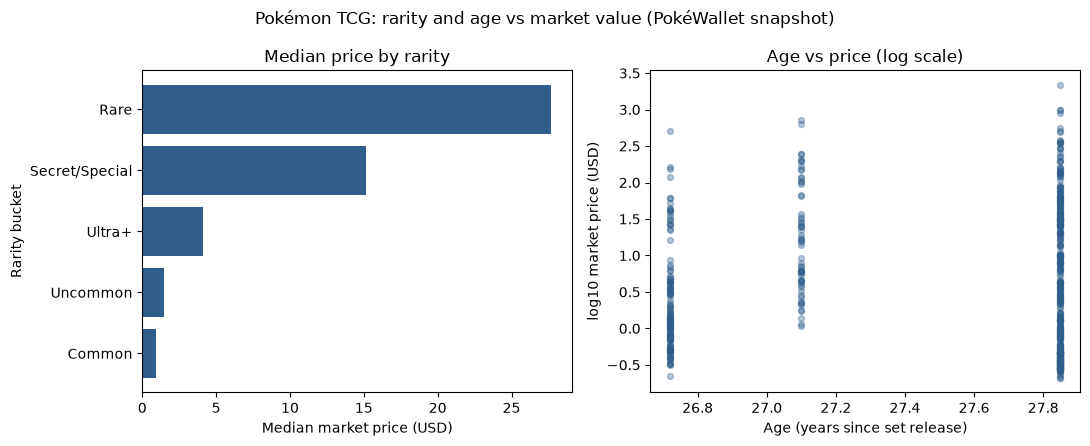

Saved figure → /Users/edgarsoberon/Documents/Web Data Science/Project/figures/rarity_age_vs_price.png
Caption: Median TCGPlayer market price rises across rarity buckets, while age vs price is weak/noisy—consistent with rarity mattering more than age alone.


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

plot_r = by_rarity.sort_values("median_usd")
axes[0].barh(plot_r["rarity_bucket"], plot_r["median_usd"], color="#2f5d8c")
axes[0].set_xlabel("Median market price (USD)")
axes[0].set_ylabel("Rarity bucket")
axes[0].set_title("Median price by rarity")

axes[1].scatter(
    df["age_years"],
    np.log10(df["market_price_usd"]),
    alpha=0.35,
    s=18,
    color="#2f5d8c",
)
axes[1].set_xlabel("Age (years since set release)")
axes[1].set_ylabel("log10 market price (USD)")
axes[1].set_title("Age vs price (log scale)")

fig.suptitle(
    "Pokémon TCG: rarity and age vs market value (PokéWallet snapshot)",
    fontsize=12,
)
fig.tight_layout()

fig_path = FIG_DIR / "rarity_age_vs_price.png"
fig.savefig(fig_path, dpi=150, bbox_inches="tight")
plt.show()

print(f"Saved figure → {fig_path}")
print(
    "Caption: Median TCGPlayer market price rises across rarity buckets, "
    "while age vs price is weak/noisy—consistent with rarity mattering more than age alone."
)

In [9]:
print("Done. Upload these for the portfolio update:")
print(" -", clean_path.relative_to(ROOT))
print(" -", sample_path.relative_to(ROOT))
print(" -", fig_path.relative_to(ROOT))
print(" - analysis.ipynb (save after Run All so outputs are visible)")

Done. Upload these for the portfolio update:
 - data/processed/cards_clean_pokewallet.csv
 - data/sample/cards_clean_pokewallet_sample.csv
 - figures/rarity_age_vs_price.png
 - analysis.ipynb (save after Run All so outputs are visible)
